In [9]:
import pandas as pd
from pathlib import Path
from shapely import from_wkt

import folium
from folium.plugins import MarkerCluster
import random

import matplotlib.pyplot as plt

SAMPLE = Path.home() / "Desktop" / "spu" / "sample"

In [2]:
def load_layer(csv_path):
    """Load one sample CSV and add lat/lon (point coords for points,
    centroid for lines/polygons) derived from geometry_wkt."""
    df = pd.read_csv(csv_path, low_memory=False)
    geoms = df["geometry_wkt"].apply(lambda w: from_wkt(w) if pd.notna(w) else None)
    centroids = geoms.apply(lambda g: g.centroid if g is not None else None)
    df["lat"] = centroids.apply(lambda c: c.y if c is not None else None)
    df["lon"] = centroids.apply(lambda c: c.x if c is not None else None)
    return df

index = pd.read_csv(SAMPLE / "_index.csv")
data = {row["label"]: load_layer(SAMPLE / row["file"]) for _, row in index.iterrows()}

In [3]:
print(f"Loaded {len(data)} layers, {sum(len(d) for d in data.values()):,} total features")
index.set_index("label")[["asset_class", "geometry_type",
                          "n_features_in_sample", "n_features_in_full",
                          "n_attributes"]]

Loaded 12 layers, 8,696 total features


,asset_class,geometry_type,n_features_in_sample,n_features_in_full,n_attributes
label,,,,,
Pump Stations,Pump Stations,Polygon,141,141,36
Appurtenance Valves,Appurtenances,Point,384,384,47
CSO Basins,Service Areas,Polygon,81,81,9
Catch Basins (sample),Collection,Point,1500,91965,34
Ditches & Culverts (sample),Conveyance,LineString,1000,26741,41
GSI Weirs,Green Infrastructure,Point,169,169,37
GSI Swales (sample),Green Infrastructure,LineString,1000,12743,31
Mainlines Permitted Use (sample),Conveyance,LineString,1500,65234,56
Ponds,Detention,Polygon,53,53,24


In [5]:
# Assign a color to each layer
palette = ["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00",
           "#a65628","#f781bf","#999999","#66c2a5","#fc8d62","#8da0cb","#e78ac3"]
color_map = {label: palette[i % len(palette)] for i, label in enumerate(data)}

m = folium.Map(location=[47.58, -122.33], zoom_start=11, tiles="CartoDB positron")
cluster = MarkerCluster().add_to(m)

for label, df in data.items():
    color = color_map[label]
    for _, row in df.dropna(subset=["lat", "lon"]).iterrows():
        folium.CircleMarker(
            location=[row["lat"], row["lon"]],
            radius=4,
            color=color,
            fill=True,
            fill_opacity=0.7,
            tooltip=label,
        ).add_to(cluster)

# Legend
legend_html = "<div style='position:fixed;bottom:30px;left:30px;background:white;padding:10px;border:1px solid grey;font-size:12px;z-index:9999'>"
for label, color in color_map.items():
    legend_html += f"<div><span style='background:{color};width:12px;height:12px;display:inline-block;margin-right:6px'></span>{label}</div>"
legend_html += "</div>"
m.get_root().html.add_child(folium.Element(legend_html))

m


In [6]:
m.save("map.html")
import webbrowser, os
webbrowser.open("file://" + os.path.abspath("map.html"))

True

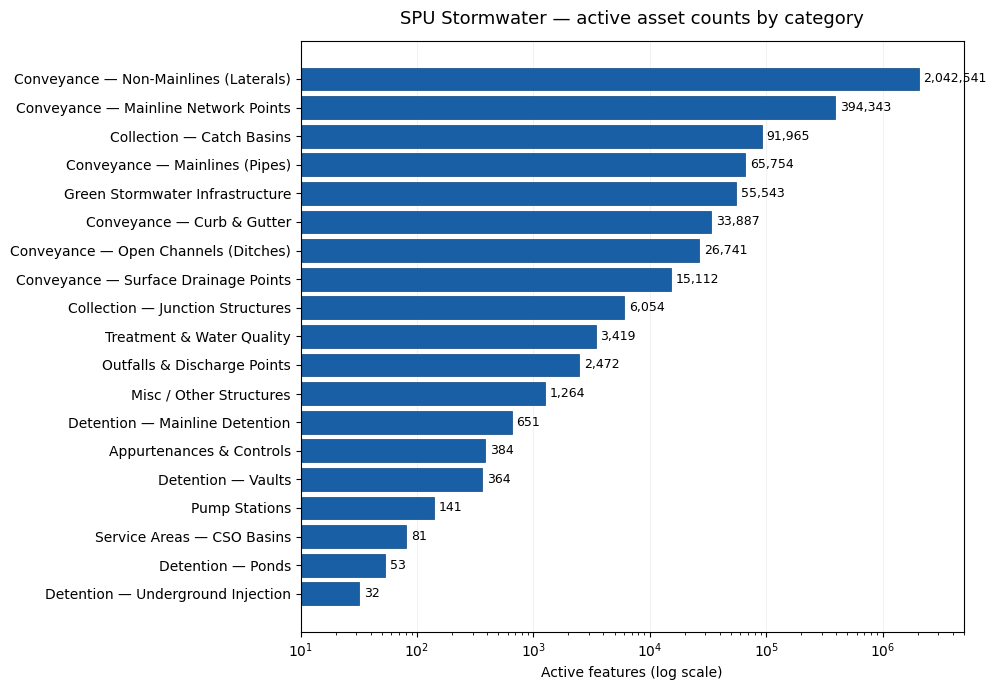

In [10]:
asset_counts = pd.DataFrame([
    ("Conveyance — Non-Mainlines (Laterals)", 2_042_541),
    ("Conveyance — Mainline Network Points", 394_343),
    ("Collection — Catch Basins", 91_965),
    ("Conveyance — Mainlines (Pipes)", 65_754),
    ("Green Stormwater Infrastructure", 55_543),
    ("Conveyance — Curb & Gutter", 33_887),
    ("Conveyance — Open Channels (Ditches)", 26_741),
    ("Conveyance — Surface Drainage Points", 15_112),
    ("Collection — Junction Structures", 6_054),
    ("Treatment & Water Quality", 3_419),
    ("Outfalls & Discharge Points", 2_472),
    ("Misc / Other Structures", 1_264),
    ("Detention — Mainline Detention", 651),
    ("Appurtenances & Controls", 384),
    ("Detention — Vaults", 364),
    ("Pump Stations", 141),
    ("Service Areas — CSO Basins", 81),
    ("Detention — Ponds", 53),
    ("Detention — Underground Injection", 32),
], columns=["asset_class", "count"]).sort_values("count")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(asset_counts["asset_class"], asset_counts["count"], color="#185FA5", edgecolor="#0C447C", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlim(10, 5_000_000)
ax.set_xlabel("Active features (log scale)")
ax.set_title("SPU Stormwater — active asset counts by category", fontsize=13, pad=12)
for i, n in enumerate(asset_counts["count"]):
    ax.text(n * 1.1, i, f"{n:,}", va="center", fontsize=9)
ax.grid(axis="x", which="major", color="0.92", linewidth=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show() 